### BCSE432E Reinforcement Learning Lab: L29+L30
### Lab Assignment 9

### REINFORCE vs Deep Q-Learning (DQN) on CartPole environment

### Name: Yashvanth Karunakaran (23BAI1589)

Notebook Link: [https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-7.ipynb](https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-7.ipynb)

### AIM:
To Develop a Python implementation of the REINFORCE algorithm to train the CartPole environment, and evaluate its performance against a Deep Q-Learning baseline.

#### Install dependencies

In [1]:
%pip install -q "gymnasium[classic-control]" torch matplotlib numpy

/home/yashix/.zshenv:.:1: no such file or directory: /home/yashix/.cargo/env
/media/yashix/New Volume/Stockify/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


#### Environment setup

In [2]:
import gymnasium as gym

SEED = 42

env = gym.make("CartPole-v1")

env.action_space.seed(SEED)
env.observation_space.seed(SEED)

state, info = env.reset(seed=SEED)

state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size)
print("Action size:", action_size)
print("Initial state:", state)
print("Actions:" , env.action_space,"0: push cart left, 1: push cart right")

State size: 4
Action size: 2
Initial state: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
Actions: Discrete(2) 0: push cart left, 1: push cart right


#### Policy network
small MLP maps the 4-dimensional state to a probability distribution over the 2 actions using a softmax output

In [3]:
import torch
import torch.nn as nn

class PolicyNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size),
            nn.Softmax(dim=-1)
        )

    def forward(self, state):
        return self.network(state)

#### REINFORCE agent
samples actions from the policy and updates it with the REINFORCE gradient using normalised discounted returns

In [4]:
import torch.optim as optim

DEVICE = "cpu"

if torch.cuda.is_available():
    DEVICE = "cuda"

class REINFORCEAgent:
    def __init__(self, state_size, action_size, learning_rate = 1e-3, gamma = 0.99):
        self.gamma = gamma

        self.policy = PolicyNetwork(state_size, action_size).to(DEVICE)

        self.optimizer = optim.Adam(self.policy.parameters(), lr = learning_rate)

    def select_action(self, state):
        state_tensor = torch.as_tensor(state, dtype = torch.float32, device = DEVICE).unsqueeze(0)
        action_probs = self.policy(state_tensor)
        action_distribution = torch.distributions.Categorical(action_probs)
        action = action_distribution.sample()
        log_prob = action_distribution.log_prob(action)
        return action.item(), log_prob

    def update(self, rewards, log_probs):
        returns = []
        G = 0
        for reward in reversed(rewards):
            G = reward + self.gamma * G
            returns.append(G)

        returns.reverse()
        returns = torch.tensor(returns, dtype = torch.float32, device = DEVICE)
        if len(returns) > 1:
            returns = (returns - returns.mean()) / (returns.std(unbiased=False) + 1e-9)

        log_probs = torch.stack(log_probs).squeeze(-1)  
        loss = -(log_probs * returns).sum()

        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.policy.parameters(), max_norm = 1.0)
        self.optimizer.step()

        return loss.item()
    

#### Training loop
Runs 1000 episodes. After each episode the agent updates its policy

In [5]:
from itertools import count
import numpy as np

REINFORCE_EPISODES = 1000

reinforce_env = gym.make("CartPole-v1")
refinforce_agent = REINFORCEAgent(state_size, action_size, learning_rate = 1e-3, gamma = 0.99)

reinforce_rewards = []

for episode in range(REINFORCE_EPISODES):
    state, info = reinforce_env.reset(seed = SEED + episode)
    log_probs = []
    episode_rewards = []

    for step in count():
        action, log_prob = refinforce_agent.select_action(state)
        next_state, reward, terminated, truncated, info = reinforce_env.step(action)

        log_probs.append(log_prob)
        episode_rewards.append(reward)

        state = next_state

        if terminated or truncated:
            break

    loss = refinforce_agent.update(episode_rewards, log_probs)
    total_reward = sum(episode_rewards)
    reinforce_rewards.append(total_reward)

    if (episode + 1) % 50 == 0:
        recent_rewards_mean = np.mean(reinforce_rewards[-50:])
        print(f"Episode {episode+1}: Mean Reward (last 50 episodes): {recent_rewards_mean:.2f}, Loss: {loss:.4f}")

reinforce_env.close()

Episode 50: Mean Reward (last 50 episodes): 24.74, Loss: -0.4073
Episode 100: Mean Reward (last 50 episodes): 34.16, Loss: 1.8662
Episode 150: Mean Reward (last 50 episodes): 76.20, Loss: -8.3024
Episode 200: Mean Reward (last 50 episodes): 128.56, Loss: -0.8694
Episode 250: Mean Reward (last 50 episodes): 116.54, Loss: -5.8691
Episode 300: Mean Reward (last 50 episodes): 182.96, Loss: -6.0717
Episode 350: Mean Reward (last 50 episodes): 343.62, Loss: -15.4729
Episode 400: Mean Reward (last 50 episodes): 154.82, Loss: -1.6887
Episode 450: Mean Reward (last 50 episodes): 121.12, Loss: -8.0103
Episode 500: Mean Reward (last 50 episodes): 221.26, Loss: 1.6748
Episode 550: Mean Reward (last 50 episodes): 141.32, Loss: -6.8107
Episode 600: Mean Reward (last 50 episodes): 175.80, Loss: -1.4494
Episode 650: Mean Reward (last 50 episodes): 382.90, Loss: -2.3138
Episode 700: Mean Reward (last 50 episodes): 127.06, Loss: -0.2702
Episode 750: Mean Reward (last 50 episodes): 274.54, Loss: -8.3586


#### Q-Network (DQN)
feed-forward network maps the 4-dimensional CartPole state to one Q-value per action

In [6]:
class QNetwork(nn.Module):

    def __init__(self, state_size, action_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size)
        )

    def forward(self, state):
        return self.network(state)

#### Replay buffer
fixed-size FIFO memory that stores past transitions (state, action, reward, next state, terminated), DQN samples random mini-batches from it

In [7]:
from collections import deque
import random   

random.seed(SEED)

class ReplayBuffer:

    def __init__(self, capacity = 50000):
        self.buffer = deque(maxlen = capacity)

    def add(self, state, action, reward, next_state, terminated):
        self.buffer.append((state, action, reward, next_state, terminated))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, terminateds = zip(*batch)
        return np.array(states), np.array(actions), np.array(rewards), np.array(next_states), np.array(terminateds)

    def __len__(self):
        return len(self.buffer)

#### DQN agent
Combines the Q-network, a target network, the replay buffer, and epsilon-greedy exploration

In [8]:
class DQNAgent:

    def __init__(self, state_size, action_size, learning_rate = 1e-3, gamma = 0.99, epsilon_start = 1.0, epsilon_end = 0.01, epsilon_decay = 0.995, epsilon_min = 0.05, batch_size = 64, target_update_freq = 10):

        self.action_size = action_size
        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.batch_size = batch_size
        self.target_update_freq = target_update_freq
        self.steps = 0

        self.q_network = QNetwork(state_size, action_size).to(DEVICE)
        self.target_network = QNetwork(state_size, action_size).to(DEVICE)
        self.target_network.load_state_dict(self.q_network.state_dict())
        self.target_network.eval()

        self.optimizer = optim.Adam(self.q_network.parameters(), lr = learning_rate)
        self.memory = ReplayBuffer()

    def select_action(self, state, training = True):
        if training and random.random() < self.epsilon:
            return random.randint(0, self.action_size - 1)
        
        state_tensor = torch.as_tensor(state, dtype = torch.float32, device = DEVICE).unsqueeze(0)
        with torch.no_grad():
            q_values = self.q_network(state_tensor)
        return q_values.argmax().item()

    def train(self):
        if len(self.memory) < self.batch_size:
            return

        states, actions, rewards, next_states, terminateds = self.memory.sample(self.batch_size)

        states_tensor = torch.as_tensor(states, dtype = torch.float32, device = DEVICE)
        actions_tensor = torch.as_tensor(actions, dtype = torch.int64, device = DEVICE).unsqueeze(-1)
        rewards_tensor = torch.as_tensor(rewards, dtype = torch.float32, device = DEVICE).unsqueeze(-1)
        next_states_tensor = torch.as_tensor(next_states, dtype = torch.float32, device = DEVICE)
        terminateds_tensor = torch.as_tensor(terminateds, dtype = torch.float32, device = DEVICE).unsqueeze(-1)

        q_values = self.q_network(states_tensor).gather(1, actions_tensor)

        with torch.no_grad():
            next_q_values = self.target_network(next_states_tensor).max(dim=1, keepdim=True)[0]
            target_q_values = rewards_tensor + (self.gamma * next_q_values * (1 - terminateds_tensor))

        loss = nn.functional.mse_loss(q_values, target_q_values)

        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.q_network.parameters(), max_norm=1.0)
        self.optimizer.step()

        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay

        self.steps += 1
        if self.steps % self.target_update_freq == 0:
            self.target_network.load_state_dict(self.q_network.state_dict())

        return loss.item()

    def end_episode(self):
        self.epsilon = max(self.epsilon * self.epsilon_decay, self.epsilon_min)
        


#### DQN training loop
training the DQN agent for 1000 episodes. at every environment step the transition is stored in the replay buffer and the agent performs one gradient update on a random mini-batch

In [9]:
DQN_EPISODES = 1000
dqn_env = gym.make("CartPole-v1")
dqn_agent = DQNAgent(state_size, action_size, learning_rate = 1e-3, gamma = 0.99, epsilon_start = 1.0, epsilon_end = 0.01, epsilon_decay = 0.995, epsilon_min = 0.05, batch_size = 64, target_update_freq = 500)

dqn_rewards = []
dqn_losses = []

for episode in range(DQN_EPISODES):
    state, info = dqn_env.reset(seed = SEED + episode)
    episode_rewards = []
    episode_losses = []

    for step in count():
        action = dqn_agent.select_action(state)
        next_state, reward, terminated, truncated, info = dqn_env.step(action)

        dqn_agent.memory.add(state, action, reward, next_state, terminated)

        loss = dqn_agent.train()
        if loss is not None:
            episode_losses.append(loss)

        episode_rewards.append(reward)
        state = next_state

        if terminated or truncated:
            break

    dqn_agent.end_episode()
    total_reward = sum(episode_rewards)
    dqn_rewards.append(total_reward)
    if episode_losses:
        avg_loss = np.mean(episode_losses)
        dqn_losses.append(avg_loss)

    if (episode + 1) % 50 == 0:
        recent_rewards_mean = np.mean(dqn_rewards[-50:])
        print(f"Episode {episode+1}: Mean Reward (last 50 episodes): {recent_rewards_mean:.2f}, Avg Loss: {avg_loss:.4f}")

Episode 50: Mean Reward (last 50 episodes): 12.82, Avg Loss: 0.0520
Episode 100: Mean Reward (last 50 episodes): 12.82, Avg Loss: 0.0434
Episode 150: Mean Reward (last 50 episodes): 56.88, Avg Loss: 0.0794
Episode 200: Mean Reward (last 50 episodes): 164.26, Avg Loss: 0.5266
Episode 250: Mean Reward (last 50 episodes): 114.74, Avg Loss: 0.1298
Episode 300: Mean Reward (last 50 episodes): 119.88, Avg Loss: 1.5121
Episode 350: Mean Reward (last 50 episodes): 119.06, Avg Loss: 0.6186
Episode 400: Mean Reward (last 50 episodes): 127.14, Avg Loss: 0.6534
Episode 450: Mean Reward (last 50 episodes): 101.16, Avg Loss: 1.2556
Episode 500: Mean Reward (last 50 episodes): 126.78, Avg Loss: 1.0439
Episode 550: Mean Reward (last 50 episodes): 152.06, Avg Loss: 1.5797
Episode 600: Mean Reward (last 50 episodes): 233.92, Avg Loss: 1.8797
Episode 650: Mean Reward (last 50 episodes): 199.04, Avg Loss: 3.1396
Episode 700: Mean Reward (last 50 episodes): 288.34, Avg Loss: 3.0040
Episode 750: Mean Reward

#### REINFORCE evaluation
Runs the trained REINFORCE policy for 100 episodes without updating it,  sampling actions from the learned distribution

In [10]:
eval_env = gym.make("CartPole-v1")
reinforce_rewards = []

for episode in range(100):
    state, info = eval_env.reset(seed = SEED + episode)
    episode_rewards = []

    while True:
        state_tensor = torch.as_tensor(state, dtype = torch.float32, device = DEVICE).unsqueeze(0)
        with torch.no_grad():
            action_probs = refinforce_agent.policy(state_tensor)
        action_distribution = torch.distributions.Categorical(action_probs)
        action = action_distribution.sample().item()

        next_state, reward, terminated, truncated, info = eval_env.step(action)
        episode_rewards.append(reward)
        state = next_state

        if terminated or truncated:
            break

    total_reward = sum(episode_rewards)
    reinforce_rewards.append(total_reward)

print(f"Average reward over 100 episodes: {np.mean(reinforce_rewards)}")
print(f"Max reward over 100 episodes: {np.max(reinforce_rewards)}")
print(f"Min reward over 100 episodes: {np.min(reinforce_rewards)}")
print(f"Standard deviation of rewards over 100 episodes: {np.std(reinforce_rewards)}")
print(f"Median reward over 100 episodes: {np.median(reinforce_rewards)}")

Average reward over 100 episodes: 497.26
Max reward over 100 episodes: 500.0
Min reward over 100 episodes: 226.0
Standard deviation of rewards over 100 episodes: 27.26265577672138
Median reward over 100 episodes: 500.0


#### DQN evaluation
Runs the trained DQN agent for 100 episodes with greedy actions (`training=False`, so no random exploration)

In [11]:
eval_env = gym.make("CartPole-v1")
dqn_rewards = []

for episode in range(100):
    state, info = eval_env.reset(seed = SEED + episode)
    episode_rewards = []

    while True:
        action = dqn_agent.select_action(state, training = False)
        next_state, reward, terminated, truncated, info = eval_env.step(action)
        episode_rewards.append(reward)
        state = next_state

        if terminated or truncated:
            break

    total_reward = sum(episode_rewards)
    dqn_rewards.append(total_reward)

print(f"Average reward over 100 episodes: {np.mean(dqn_rewards)}")
print(f"Max reward over 100 episodes: {np.max(dqn_rewards)}")
print(f"Min reward over 100 episodes: {np.min(dqn_rewards)}")
print(f"Standard deviation of rewards over 100 episodes: {np.std(dqn_rewards)}")
print(f"Median reward over 100 episodes: {np.median(dqn_rewards)}")

Average reward over 100 episodes: 103.94
Max reward over 100 episodes: 113.0
Min reward over 100 episodes: 96.0
Standard deviation of rewards over 100 episodes: 3.8152850483286307
Median reward over 100 episodes: 103.5


#### Smoothing the reward curves
applied with a 10-episode window to the REINFORCE and DQN training rewards

In [12]:
def moving_average(data, window_size):
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

reinforce_ma = moving_average(reinforce_rewards, 10)
dqn_ma = moving_average(dqn_rewards, 10)

#### Comparison plot: REINFORCE vs DQN

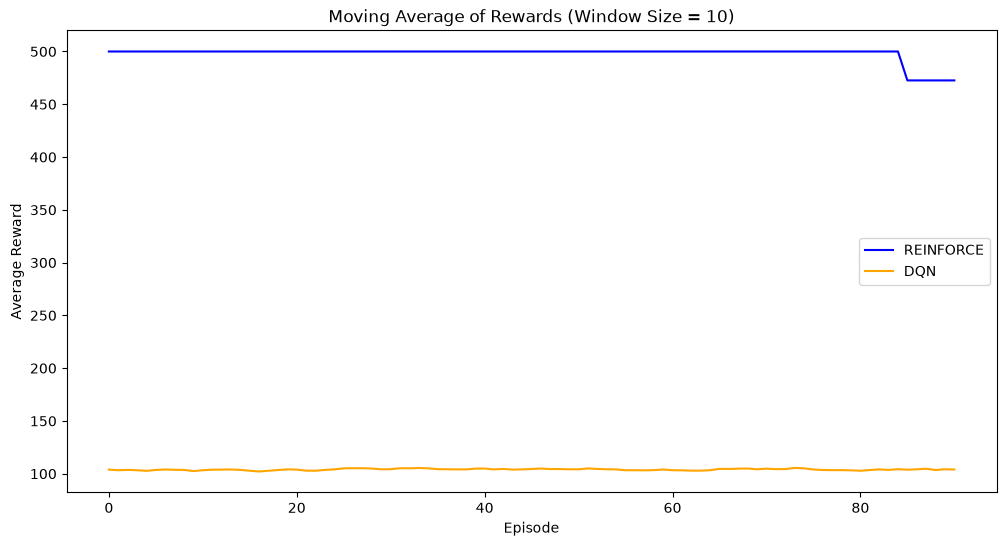

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(reinforce_ma, label='REINFORCE', color='blue')
plt.plot(dqn_ma, label='DQN', color='orange')
plt.title('Moving Average of Rewards (Window Size = 10)')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.legend()
plt.show()

#### Summary results table

In [14]:
import pandas as pd

reinforce_rewards_array = np.asarray(reinforce_rewards)
dqn_rewards_array = np.asarray(dqn_rewards)

results = pd.DataFrame({
    "Metric": [
        "Mean evaluation reward",
        "Median evaluation reward",
        "Evaluation reward std",
        "Success rate (%)",
        "Mean reward (last 100)"
    ],
    "REINFORCE": [
        np.mean(reinforce_rewards_array),
        np.median(reinforce_rewards_array),
        np.std(reinforce_rewards_array),
        np.mean(reinforce_rewards_array >= 500) * 100,
        np.mean(reinforce_rewards_array[-100:])
    ],
    "DQN": [
        np.mean(dqn_rewards_array),
        np.median(dqn_rewards_array),
        np.std(dqn_rewards_array),
        np.mean(dqn_rewards_array >= 500) * 100,
        np.mean(dqn_rewards_array[-100:])
    ]
})

display(results.round(2))

,Metric,REINFORCE,DQN
0,Mean evaluation reward,497.26,103.94
1,Median evaluation reward,500.00,103.50
2,Evaluation reward std,27.26,3.82
3,Success rate (%),99.00,0.00
4,Mean reward (last 100),497.26,103.94


#### Conclusion
In this experiment, REINFORCE performed substantially better than DQN on the CartPole-v1 environment. Over 100 evaluation episodes, REINFORCE achieved a mean reward of 497.26, a median of 500, and a success rate of 99%. DQN achieved a mean reward of 103.94 and a success rate of 0%